In [78]:
import numpy as np
import scanpy as sc
import squidpy as sq

from gctsvg.preprocessing import common

In [105]:
adata_st = sc.read("data_repo/Mouse Cerebellum/rodriques_slideseq.h5ad")

In [106]:
adata_st

AnnData object with n_obs × n_vars = 32701 × 6942
    obsm: 'spatial'

In [107]:
is_mt_gene = lambda adata: adata_st.var.index.str.startswith("mt-")
adata_st = common.filter(adata_st, min_locs=50, min_genes=20, is_mt_gene=is_mt_gene)
adata_st

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/scanpy/preprocessing/_simple.py:170: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["n_genes"] = number


AnnData object with n_obs × n_vars = 21848 × 6601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    obsm: 'spatial'

In [108]:
common.compute_hvgs(adata_st)
adata_st = adata_st[:, adata_st.var['highly_variable']]
adata_st

View of AnnData object with n_obs × n_vars = 21848 × 3000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    obsm: 'spatial'

In [109]:
sc.write("data_repo/Mouse Cerebellum/adata_preprocessed.h5ad", adata_st)

## Representation Learning
```bash
python RepresentationLearning.py --project "Mouse Cerebellum" \
--data.filename "data_repo/Mouse Cerebellum/adata_preprocessed.h5ad" \
--data.preprocess \
--model.n_in 3000 --model.n_out 200 \
--trainer.accelerator gpu --trainer.strategy ddp --trainer.num_nodes 1 --trainer.devices 1, \
--trainer.num_epochs 1000 --trainer.batch_size 5462
```

## Clustering
```bash
python Clustering.py --project "Mouse Cerebellum" \
--resolution 0.1
```

## Classifier
```bash
python Classifier.py --project "Mouse Cerebellum" \
--model.n_in 200 --model.n_out 5 \
--trainer.accelerator gpu --trainer.strategy ddp --trainer.num_nodes 1 --trainer.devices 1, \
--trainer.num_epochs 1000 --trainer.batch_size 400
```

## Attribution
```bash
PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True python Attribution.py --project "Mouse Cerebellum" \
--trainer.accelerator gpu --trainer.strategy ddp --trainer.num_nodes 1 \
--trainer.devices 1, --trainer.batch_size 25 \
--attribution.method ig
```



In [60]:
adata_clusters_filename = "gctsvg_output/Mouse Cerebellum/clustering/adata_clusters.h5ad"
adata_clusters = sc.read(adata_clusters_filename)

In [61]:
adata_clusters

AnnData object with n_obs × n_vars = 21848 × 3000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'leiden'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors'
    obsm: 'embedding', 'spatial'
    layers: 'original', 'reconstruction'
    obsp: 'connectivities', 'distances'

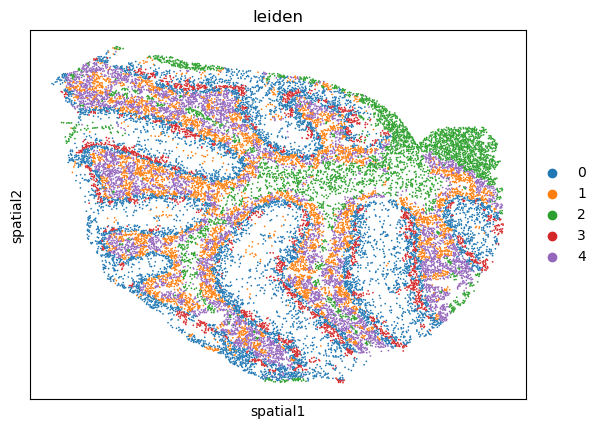

In [62]:
adata_clusters.obsm["spatial"] = adata_clusters.obsm["spatial"].to_numpy()
sc.pl.embedding(adata_clusters, s=6, basis='spatial', color='leiden')

In [67]:
adata_clusters[66].obs['leiden']

barcodes
CCAAACTCGGGGGC    3
Name: leiden, dtype: category
Categories (1, object): ['3']

In [69]:
adata_attribution_filename = "gctsvg_output/Mouse Cerebellum/st_attribution/version_5/attribution/adata_attribution.h5ad"
adata_attribution = sc.read(adata_attribution_filename)

In [76]:
adata_attribution

AnnData object with n_obs × n_vars = 21848 × 3000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'leiden'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors'
    obsm: 'embedding', 'spatial'
    layers: 'attribution', 'original', 'reconstruction'
    obsp: 'connectivities', 'distances'

In [74]:
type(adata_attribution.layers['attribution'])

numpy.ndarray

In [112]:
adata_attribution.layers['attribution'].max()

0.72422945

In [81]:
attr_aggregate = sc.get.aggregate(adata_attribution, by='leiden', layer='attribution', func=["mean"])

In [82]:
attr_aggregate

AnnData object with n_obs × n_vars = 5 × 3000
    obs: 'leiden'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    layers: 'mean'

In [114]:
attr_aggregate.layers['mean'].max()

0.28464410194932194

In [121]:
mean_attributions = attr_aggregate.layers['mean']
mean_attributions

(5, 3000)

In [135]:
k = 10
top_indices_per_cluster = np.argsort(mean_attributions, axis=1)[:, -k:]
top_indices_per_cluster

array([[1072, 1275,  364, 2061,  268, 2450, 1830,  391, 1831,  158],
       [ 508,  600, 2758, 1831, 2450, 1925, 2748, 1628,  268,  158],
       [1628, 2043,  158,  393, 2450,  622, 1474,  268, 2758, 1925],
       [1072, 1275,  268,  364, 2450, 2061,  391,  158, 1830, 1831],
       [ 374, 2758,  508, 2748,  600, 1474,  268, 1628,  158, 1925]])

In [137]:
top_genes = np.unique(top_indices_per_cluster)

In [180]:
top_genes

array([ 158,  268,  364,  374,  391,  393,  508,  600,  622, 1072, 1275,
       1474, 1628, 1830, 1831, 1925, 2043, 2061, 2450, 2748, 2758])

In [169]:
top_gene_names = adata_attribution.var.index[top_genes].values
top_gene_names

array(['Aldoc', 'Atp1b1', 'Calb1', 'Camk4', 'Car8', 'Cartpt', 'Chgb',
       'Cplx2', 'Cst3', 'Gng13', 'Itpr1', 'Mbp', 'Nap1l5', 'Pcp2', 'Pcp4',
       'Plp1', 'Ptgds', 'Pvalb', 'Sparcl1', 'Ttc3', 'Ttr'], dtype=object)

In [174]:
adata_attribution.layers['original'].max()

99.0

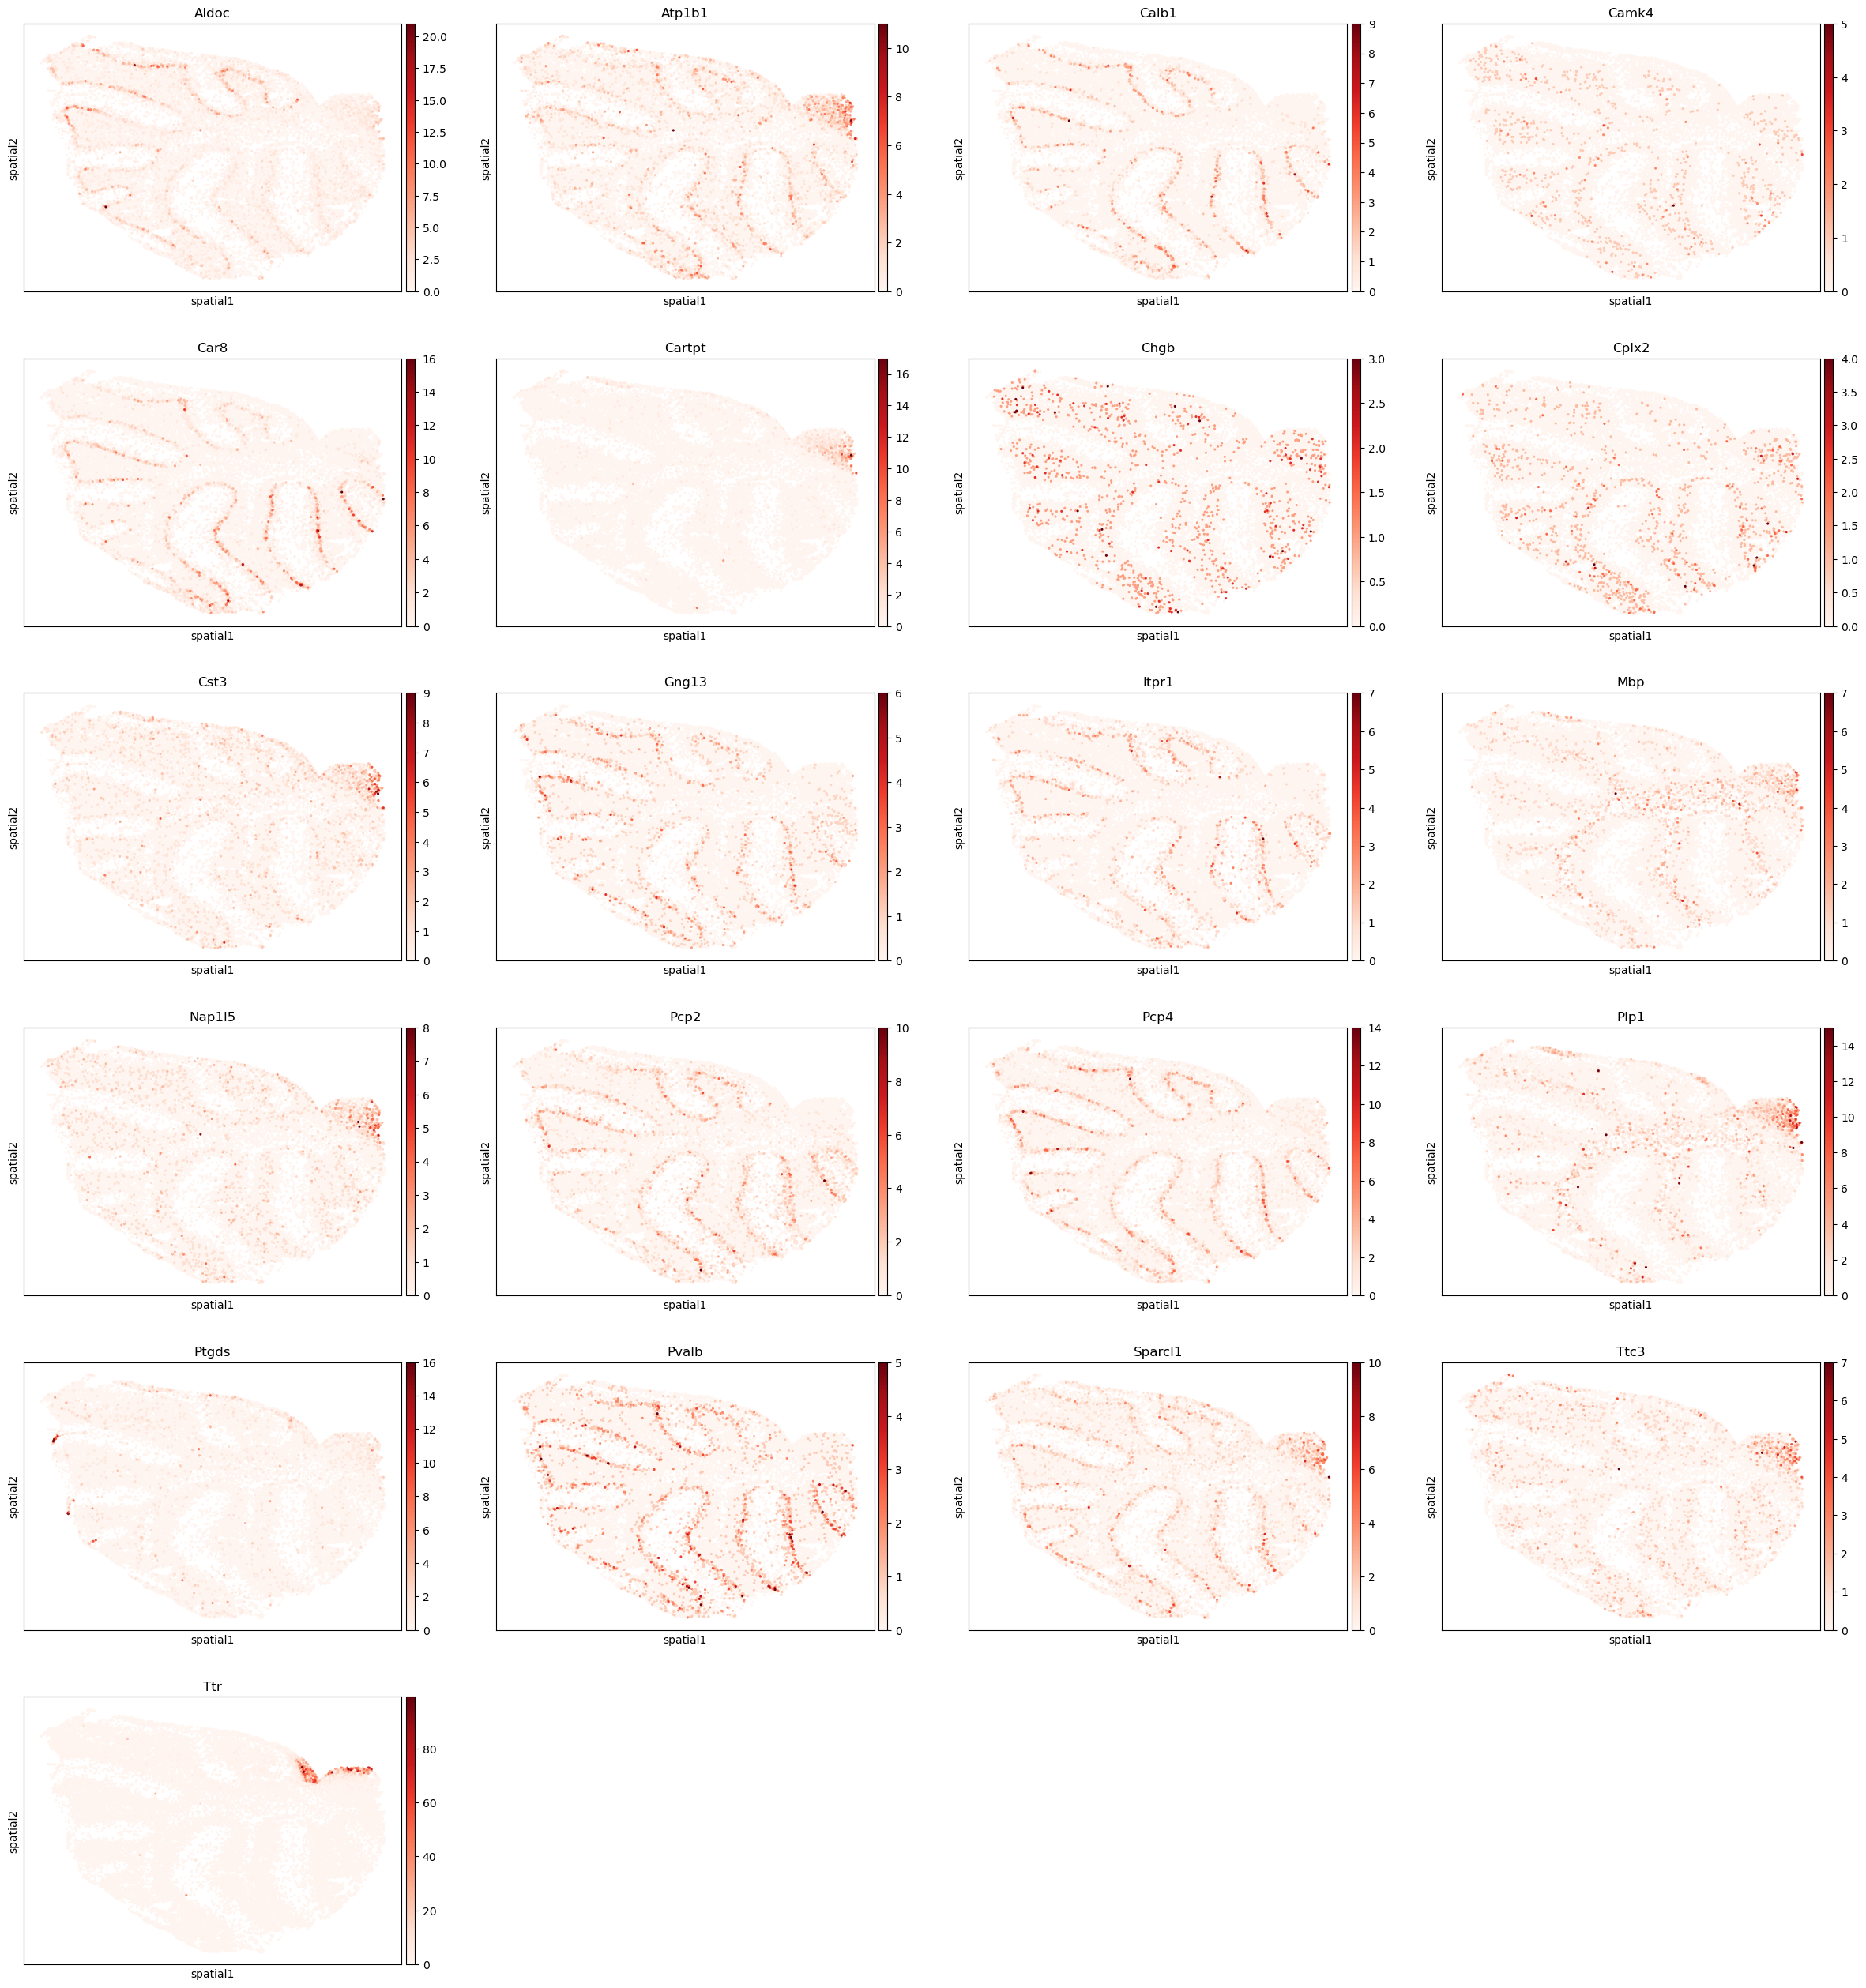

In [177]:
# adata_attribution.obsm["spatial"] = adata_attribution.obsm["spatial"].to_numpy()
sc.pl.embedding(adata_attribution, s=20, basis='spatial', layer='original', color=top_gene_names, cmap='Reds')

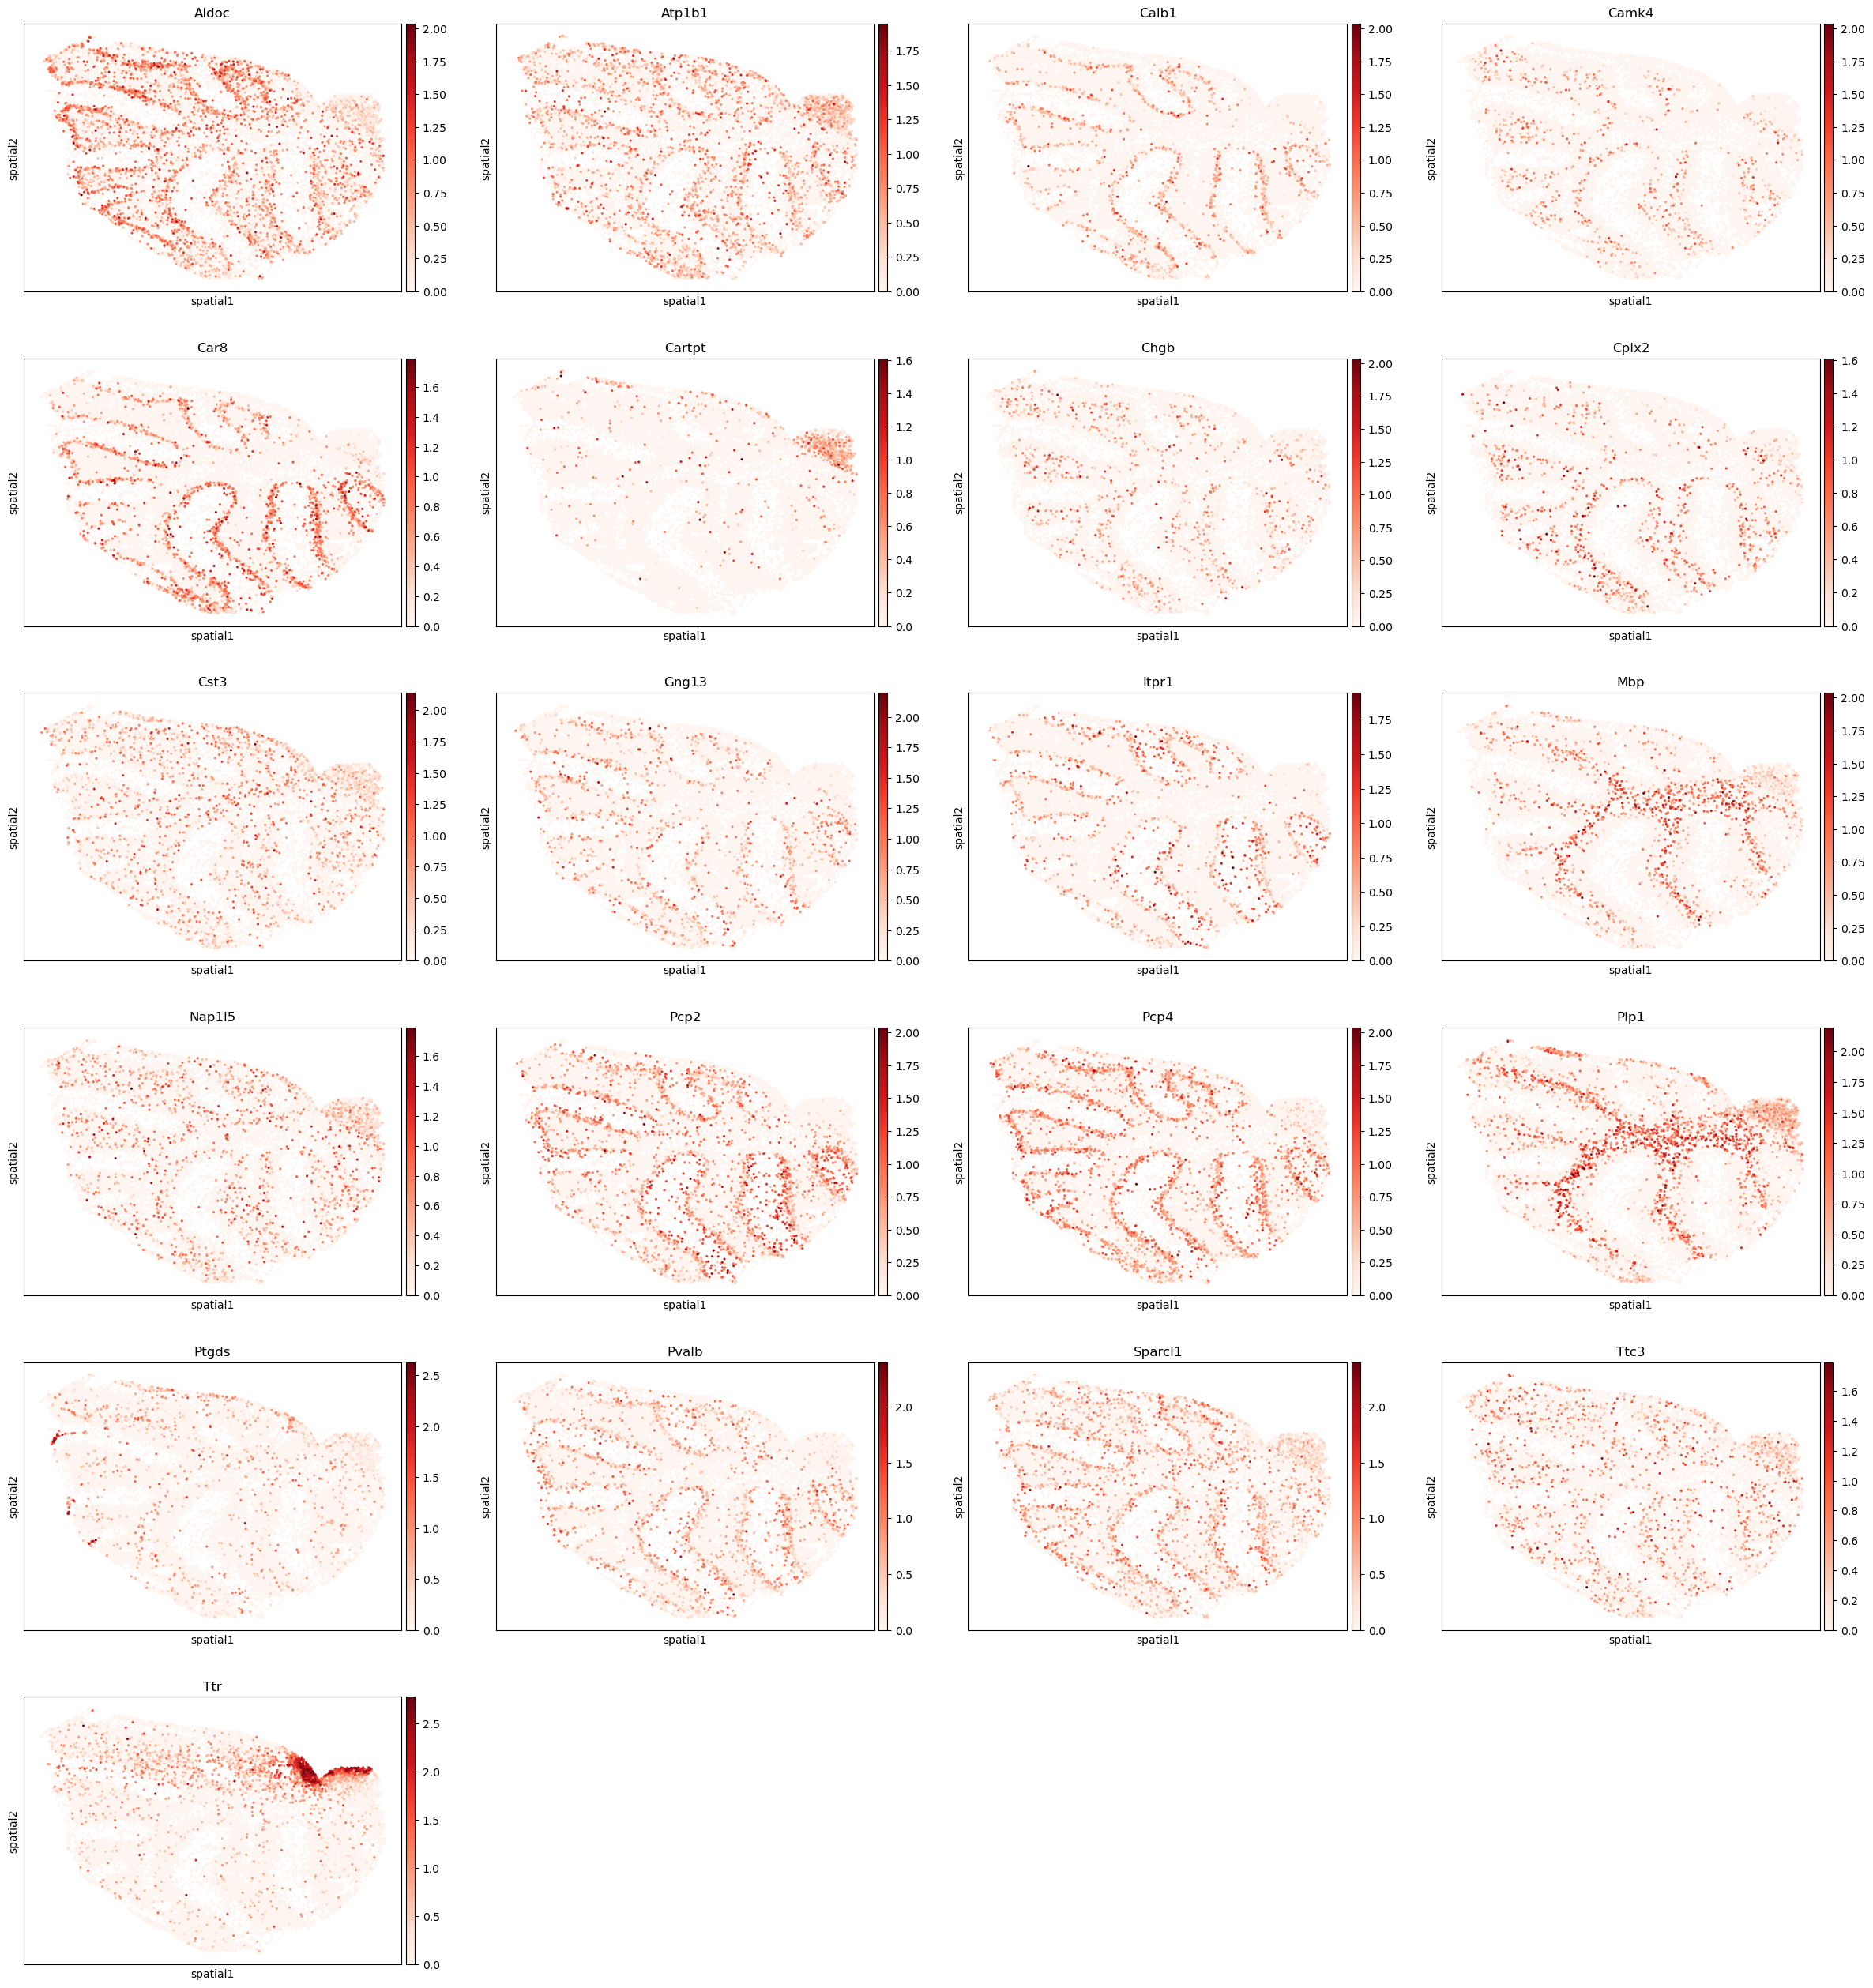

In [179]:
sc.pl.embedding(adata_attribution, s=20, basis='spatial', color=top_gene_names, cmap='Reds')

In [188]:
adata_attribution.obsm['embedding'].max()

2.38806

In [143]:
mean_attributions[:, top_genes]

array([[0.14900467, 0.09914756, 0.07631942, 0.00978718, 0.12631389,
        0.00543365, 0.01490649, 0.01556627, 0.04419473, 0.06645716,
        0.06958386, 0.0096668 , 0.03839678, 0.1163093 , 0.14429421,
        0.0193522 , 0.01793986, 0.09156351, 0.10384795, 0.03592613,
        0.02823418],
       [0.05068672, 0.03626651, 0.0106828 , 0.02405216, 0.01743662,
        0.00394026, 0.02555658, 0.02588656, 0.02218547, 0.01082167,
        0.00735225, 0.01907927, 0.02892304, 0.0207981 , 0.02600423,
        0.02761747, 0.01420997, 0.01508263, 0.02651347, 0.02777446,
        0.0259651 ],
       [0.0921413 , 0.13755106, 0.00650501, 0.00782553, 0.01273766,
        0.09787443, 0.01893042, 0.01683428, 0.11441822, 0.00983186,
        0.0066337 , 0.13513736, 0.08513881, 0.02058944, 0.02699321,
        0.2846441 , 0.09211711, 0.02216245, 0.11145249, 0.07555574,
        0.17729464],
       [0.23258862, 0.14657747, 0.15951178, 0.00280561, 0.21721473,
        0.00565267, 0.0080838 , 0.00642939, 0.0720511

In [133]:
top_attributions_per_cluster = np.take_along_axis(mean_attributions, top_indices_per_cluster, axis=1)
top_attributions_per_cluster

array([[0.06645716, 0.06958386, 0.07631942, 0.09156351, 0.09914756,
        0.10384795, 0.1163093 , 0.12631389, 0.14429421, 0.14900467],
       [0.02555658, 0.02588656, 0.0259651 , 0.02600423, 0.02651347,
        0.02761747, 0.02777446, 0.02892304, 0.03626651, 0.05068672],
       [0.08513881, 0.09211711, 0.0921413 , 0.09787443, 0.11145249,
        0.11441822, 0.13513736, 0.13755106, 0.17729464, 0.2846441 ],
       [0.13566507, 0.14110411, 0.14657747, 0.15951178, 0.18469835,
        0.1974548 , 0.21721473, 0.23258862, 0.24186598, 0.26140677],
       [0.04356479, 0.04391999, 0.04413624, 0.04513437, 0.0499131 ,
        0.04991381, 0.05177527, 0.05410754, 0.06793113, 0.07963148]])

In [ ]:
top_k_values_unsorted = np.partition(matrix.flatten(), -k)[-k:]

In [84]:
attr_aggregate.obs["leiden"]

0    0
1    1
2    2
3    3
4    4
Name: leiden, dtype: category
Categories (5, object): ['0', '1', '2', '3', '4']

In [97]:
attr_mean = attr_aggregate.layers["mean"].mean(axis=1)
attr_mean

array([0.0045424 , 0.00286941, 0.00655415, 0.00594998, 0.00466558])

In [101]:
attr_mean.T

array([0.0045424 , 0.00286941, 0.00655415, 0.00594998, 0.00466558])

In [106]:
attr_candidate = (attr_aggregate.layers["mean"].T > attr_mean).T
attr_candidate

array([[ True, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [ True,  True, False, ..., False, False,  True],
       [False, False, False, ...,  True,  True, False]])

In [110]:
attr_candidate.sum(axis=1)

array([817, 893, 843, 743, 887])